# GSEA WT 3v3: top and cross-center consistent terms

This notebook summarizes the CPM-filtered rerun in `GSEA_expanded_WT_3v3/full_observed_results.csv`; it does **not** rerun GSEA. The primary statistic is `NES_WT`, with `q_WT` from the source-adjusted WT-versus-WT 3v3 empirical reference. Observed enrichment scores use all eligible KO and control samples in each original comparison.

**Expression filter applied:** ranked genes have `max(mean CPM in KO, mean CPM in WT) >= 1` in that target/comparison. The active analysis retains the original representative locus per symbol, then applies the CPM filter before GSEA scoring, and the same retained gene-ID universe is used for the corresponding WT 3v3 pseudo-comparisons. The prior unfiltered result folder is retained unchanged.

The goal is to distinguish two questions:

1. **Top within one comparison:** smallest collection-specific `q_WT`, then largest `|NES_WT|`.
2. **Consistent across comparisons:** recurrent significance with the same enrichment direction across JAX, MSK, UCSF, NW, and NW-parent for one perturbed gene. NKX2-1/MSK is excluded from term selection and display because of its documented differentiation failure.

Positive NES means the gene set is concentrated toward genes increased in KO relative to control; negative NES means concentration toward genes decreased in KO.

This copy reads the active results directly. The ranking, selection, and plotting code is unchanged from the GitHub notebook. Outputs were regenerated by sequential Rscript evaluation.

Data location: the loader checks `MORPHIC_GSEA_DIR`, then `MORPHIC_DE_RESULTS`, relative locations, and the current machine’s active data directory. On another machine, set `MORPHIC_GSEA_DIR` before running. It reads existing results and does not rerun GSEA.


In [1]:
suppressPackageStartupMessages({
  library(data.table)
  library(dplyr)
  library(ggplot2)
  library(stringr)
  library(scales)
})

theme_set(theme_classic(base_size = 12))
options(repr.plot.width = 14, repr.plot.height = 15, repr.plot.res = 130)

target_order <- c("EOMES", "GCM1", "ISL1", "NKX2-1")
contrast_order <- c("JAX", "MSK", "UCSF", "NW", "NW_parent")
collection_order <- c("Hallmark", "Reactome", "GO_BP", "ReMap", "Custom_ChIP")

q_cutoff <- 0.05
min_direction_fraction <- 0.80
min_significant_contrasts <- 3L # significant in the consensus direction
top_n_per_direction <- 3L

# Resolve active results from an explicit override, relative paths, or this machine's data directory.
# Optional: Sys.setenv(MORPHIC_GSEA_DIR = "/absolute/path/to/GSEA_expanded_WT_3v3")
configured_dir <- Sys.getenv("MORPHIC_GSEA_DIR", unset = "")
de_results_dir <- Sys.getenv("MORPHIC_DE_RESULTS", unset = "")
candidate_dirs <- c(
  if (nzchar(configured_dir)) path.expand(configured_dir),
  if (nzchar(de_results_dir)) file.path(path.expand(de_results_dir), "GSEA_expanded_WT_3v3"),
  "GSEA_expanded_WT_3v3",
  file.path("..", "GSEA_expanded_WT_3v3"),
  file.path("scripts", "GSEA_expanded_WT_3v3"),
  "/Users/wsun/Library/CloudStorage/GoogleDrive-weisun2013@gmail.com/.shortcut-targets-by-id/1lCtheIStsu48LzXmlVBrG9cZQ_6bzYEF/1. MorPhiC-Consortium/4. DRACC DPC DAV Research documents/Exchange_experiment/Analysis Plan/DE_results/GSEA_expanded_WT_3v3"
)
valid_dir <- function(d) all(file.exists(file.path(d, c(
  "full_observed_results.csv", "input_manifest.json", "ANALYSIS_COMPLETED"))))
if (nzchar(configured_dir) && !valid_dir(path.expand(configured_dir))) {
  stop("MORPHIC_GSEA_DIR does not contain completed active results: ", configured_dir)
}
valid_dirs <- candidate_dirs[vapply(candidate_dirs, valid_dir, logical(1))]
if (!length(valid_dirs)) stop("Set MORPHIC_GSEA_DIR to the active GSEA_expanded_WT_3v3 directory.")
gsea_dir <- normalizePath(valid_dirs[1], mustWork = TRUE)
gsea_results_file <- file.path(gsea_dir, "full_observed_results.csv")
manifest <- jsonlite::fromJSON(file.path(gsea_dir, "input_manifest.json"))
stopifnot(file.exists(gsea_results_file),
          grepl("q75_pass", manifest$filter, fixed=TRUE),
          grepl(">= 1", manifest$filter, fixed=TRUE),
          identical(readLines(file.path(gsea_dir, "ANALYSIS_COMPLETED")), manifest$run_fingerprint))
cat("Direct results MD5:", unname(tools::md5sum(gsea_results_file)), "\n")

required_columns <- c(
  "target", "contrast", "collection", "pathway", "size", "ES",
  "p_WT", "NES_WT", "q_WT", "p_prerank", "NES_prerank", "q_prerank"
)

gsea_results <- data.table::fread(
  gsea_results_file,
  select = required_columns,
  data.table = FALSE
) %>%
  mutate(
    target = factor(target, levels = target_order),
    contrast = factor(contrast, levels = contrast_order, ordered = TRUE),
    collection = factor(collection, levels = collection_order),
    term_label = case_when(
      collection == "ReMap" ~ str_remove(pathway, "^REMAP__"),
      TRUE ~ pathway %>%
        str_remove("^(HALLMARK_|REACTOME_|GOBP_|CUSTOM_CHIP__)") %>%
        str_replace_all("_", " ")
    )
  )

duplicate_keys <- gsea_results %>%
  count(target, contrast, collection, pathway) %>%
  filter(n != 1)
stopifnot(nrow(duplicate_keys) == 0)

# Keep the complete source table intact, but omit the failed NKX2-1/MSK
# comparison from cross-center selection and the final heatmaps.
selection_results <- gsea_results %>%
  filter(!(as.character(target) == "NKX2-1" & as.character(contrast) == "MSK"))

cat("Loaded", format(nrow(gsea_results), big.mark = ","), "pathway-comparison results from", gsea_dir, "\n")

Direct results MD5: 6304f64456a631fd3dd174722ebe802f 
Loaded 97,501 pathway-comparison results from /Users/wsun/Library/CloudStorage/GoogleDrive-weisun2013@gmail.com/.shortcut-targets-by-id/1lCtheIStsu48LzXmlVBrG9cZQ_6bzYEF/1. MorPhiC-Consortium/4. DRACC DPC DAV Research documents/Exchange_experiment/Analysis Plan/DE_results/GSEA_expanded_WT_3v3 


## What the retained folder currently selects

The complete table contains every tested term. `q_WT` is BH-adjusted **within each target, comparison, and collection**, before display selection. The retained overview is not a cross-center consistency analysis:

- all 50 Hallmark sets are shown;
- previously selected Reactome and ReMap rows are frozen in `inputs/Reactome_ReMap_display_selection.csv`;
- the saved selection has three positive and three negative rows per target and collection, identified through a single comparison and `selection_abs_WT_NES`;
- previously selected nonredundant GO rows are also kept fixed; and
- the one custom ChIP set is shown directly.

Therefore, a row can appear in the overview because it had a large effect in one comparison, even if it is not significant or directionally consistent across the other comparisons. The audit below verifies this directly from the retained selection table.

In [2]:
result_scope <- gsea_results %>%
  group_by(target, collection) %>%
  summarise(
    comparisons = n_distinct(contrast),
    tested_terms = n_distinct(pathway),
    significant_term_comparisons = sum(q_WT < q_cutoff, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  arrange(target, collection)

result_scope

# A tibble: 20 × 5
   target collection  comparisons tested_terms significant_term_comparisons
   <fct>  <fct>             <int>        <int>                        <int>
 1 EOMES  Hallmark              5           50                           74
 2 EOMES  Reactome              5          977                          479
 3 EOMES  GO_BP                 5         3714                         3205
 4 EOMES  ReMap                 5          294                           47
 5 EOMES  Custom_ChIP           5            1                            5
 6 GCM1   Hallmark              5           49                           49
 7 GCM1   Reactome              5          928                          511
 8 GCM1   GO_BP                 5         3539                          558
 9 GCM1   ReMap                 5          294                          337
10 GCM1   Custom_ChIP           5            1                            0
11 ISL1   Hallmark              5           50                       

In [3]:
display_selection_file <- file.path(gsea_dir, "inputs", "Reactome_ReMap_display_selection.csv")
stopifnot(file.exists(display_selection_file))

display_selection <- data.table::fread(display_selection_file, data.table = FALSE)

display_selection_audit <- display_selection %>%
  left_join(
    gsea_results %>%
      transmute(
        selected_for_target = as.character(target),
        selection_contrast = as.character(contrast),
        collection = as.character(collection),
        pathway, current_NES_WT = NES_WT, current_q_WT = q_WT
      ),
    by = c("selected_for_target", "selection_contrast", "collection", "pathway")
  )

display_selection_audit %>%
  group_by(collection, selected_for_target, selected_for_direction) %>%
  summarise(
    selected_rows = n(),
    currently_significant = sum(current_q_WT < q_cutoff, na.rm = TRUE),
    currently_not_significant = sum(current_q_WT >= q_cutoff, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  arrange(collection, selected_for_target, selected_for_direction)

# A tibble: 16 × 6
   collection selected_for_target selected_for_direction selected_rows currently_significant currently_not_significant
   <chr>      <chr>               <chr>                          <int>                 <int>                     <int>
 1 ReMap      EOMES               down                               3                     3                         0
 2 ReMap      EOMES               up                                 3                     3                         0
 3 ReMap      GCM1                down                               3                     2                         1
 4 ReMap      GCM1                up                                 3                     2                         1
 5 ReMap      ISL1                down                               3                     0                         3
 6 ReMap      ISL1                up                                 3                     0                         3
 7 ReMap      NKX2-1         

## Reproducible definitions used here

For each gene perturbation and collection, terms are summarized over the available comparisons. NKX2-1/MSK is omitted from this summary and from the heatmaps; the complete source table is unchanged. A term is flagged `consistent_WT` when:

- at least 80% of available comparisons have the same NES sign (4/5 for EOMES, GCM1, and ISL1; 4/4 for NKX2-1); and
- at least three available comparisons have `q_WT < 0.05` in that consensus direction.

Terms are ranked separately within each gene perturbation, collection, and consensus direction by: (1) number of significant comparisons in the consensus direction, (2) sign agreement, (3) support from both WT and preranked references, (4) median absolute WT NES, (5) best WT q-value, and (6) pathway identifier as a deterministic tie-breaker. The selected display terms are the top three positive and top three negative terms from those rankings.

`consistent_both_references` is a stricter sensitivity flag requiring at least three comparisons to be significant and directionally concordant under both `q_WT`/`NES_WT` and `q_prerank`/`NES_prerank`. It does not replace the primary WT-reference result. Counts across centers are descriptive reproducibility summaries, not a pooled p-value or an additional FDR procedure.

In [4]:
# Top terms for an individual comparison: q_WT first, then absolute NES_WT.
top_per_contrast <- selection_results %>%
  group_by(target, contrast, collection) %>%
  arrange(q_WT, desc(abs(NES_WT)), pathway, .by_group = TRUE) %>%
  mutate(rank_within_contrast = row_number()) %>%
  filter(rank_within_contrast <= 10L) %>%
  ungroup()

# Compact example; change these filters to inspect another target or collection.
top_per_contrast %>%
  filter(target == "EOMES", collection == "Hallmark", rank_within_contrast <= 3L) %>%
  transmute(contrast, rank = rank_within_contrast, term = term_label, NES_WT = round(NES_WT, 3), q_WT = signif(q_WT, 3))

# A tibble: 15 × 5
   contrast   rank term                              NES_WT    q_WT
   <ord>     <int> <chr>                              <dbl>   <dbl>
 1 JAX           1 EPITHELIAL MESENCHYMAL TRANSITION   4.62 0.00492
 2 JAX           2 HYPOXIA                             2.80 0.00492
 3 JAX           3 UV RESPONSE DN                      2.77 0.00492
 4 MSK           1 EPITHELIAL MESENCHYMAL TRANSITION   4.49 0.00532
 5 MSK           2 ESTROGEN RESPONSE EARLY            -2.87 0.00532
 6 MSK           3 KRAS SIGNALING UP                   2.62 0.00532
 7 UCSF          1 TNFA SIGNALING VIA NFKB             3.43 0.00531
 8 UCSF          2 EPITHELIAL MESENCHYMAL TRANSITION   3.33 0.00531
 9 UCSF          3 ESTROGEN RESPONSE EARLY             2.88 0.00531
10 NW            1 EPITHELIAL MESENCHYMAL TRANSITION   4.08 0.00456
11 NW            2 HYPOXIA                             3.67 0.00456
12 NW            3 UV RESPONSE DN                      2.96 0.00456
13 NW_parent     1 EPITHELIAL

In [5]:
term_consistency <- selection_results %>%
  group_by(target, collection, pathway, term_label) %>%
  group_modify(function(.x, .y) {
    n_positive <- sum(.x$NES_WT > 0, na.rm = TRUE)
    n_negative <- sum(.x$NES_WT < 0, na.rm = TRUE)
    consensus_sign <- if (n_positive >= n_negative) 1 else -1
    in_consensus_direction <- sign(.x$NES_WT) == consensus_sign
    both_reference_support <-
      .x$q_WT < q_cutoff &
      .x$q_prerank < q_cutoff &
      sign(.x$NES_WT) == consensus_sign &
      sign(.x$NES_prerank) == consensus_sign

    tibble(
      n_contrasts = nrow(.x),
      consensus_direction = if (consensus_sign > 0) "positive" else "negative",
      n_direction_agree = max(n_positive, n_negative),
      direction_fraction = max(n_positive, n_negative) / nrow(.x),
      n_sig_WT = sum(.x$q_WT < q_cutoff, na.rm = TRUE),
      n_sig_consensus = sum(.x$q_WT < q_cutoff & in_consensus_direction, na.rm = TRUE),
      n_sig_both_references = sum(both_reference_support, na.rm = TRUE),
      median_NES_WT = median(.x$NES_WT, na.rm = TRUE),
      median_abs_NES_WT = median(abs(.x$NES_WT), na.rm = TRUE),
      best_q_WT = min(.x$q_WT, na.rm = TRUE),
      significant_contrasts = paste(as.character(.x$contrast[.x$q_WT < q_cutoff & in_consensus_direction]), collapse = ", ")
    )
  }) %>%
  ungroup() %>%
  mutate(
    consistent_WT =
      n_direction_agree >= ceiling(min_direction_fraction * n_contrasts) &
      n_sig_consensus >= min_significant_contrasts,
    consistent_both_references =
      consistent_WT & n_sig_both_references >= min_significant_contrasts,
    consensus_direction = factor(consensus_direction, levels = c("positive", "negative"))
  ) %>%
  arrange(
    target, collection, consensus_direction,
    desc(n_sig_consensus),
    desc(direction_fraction),
    desc(n_sig_both_references),
    desc(median_abs_NES_WT),
    best_q_WT, pathway
  ) %>%
  group_by(target, collection, consensus_direction) %>%
  mutate(rank_in_direction = row_number()) %>%
  ungroup()

priority_terms <- term_consistency %>%
  filter(rank_in_direction <= top_n_per_direction)

show_top_terms <- function(gene) {
  priority_terms %>%
    filter(target == gene) %>%
    transmute(
      collection,
      direction_rank = rank_in_direction,
      term = term_label,
      direction = consensus_direction,
      direction_agreement = percent(direction_fraction, accuracy = 1),
      WT_significant = paste0(n_sig_consensus, "/", n_contrasts),
      both_references = paste0(n_sig_both_references, "/", n_contrasts),
      median_NES_WT = round(median_NES_WT, 3),
      best_q_WT = signif(best_q_WT, 3),
      consistent_WT,
      consistent_both_references
    ) %>%
    as.data.frame()
}

consistency_counts <- term_consistency %>%
  group_by(target, collection) %>%
  summarise(
    tested_terms = n(),
    consistent_WT = sum(consistent_WT),
    consistent_both_references = sum(consistent_both_references),
    .groups = "drop"
  ) %>%
  arrange(target, collection)

consistency_counts

# A tibble: 20 × 5
   target collection  tested_terms consistent_WT consistent_both_references
   <fct>  <fct>              <int>         <int>                      <int>
 1 EOMES  Hallmark              50            13                         13
 2 EOMES  Reactome             977            39                         37
 3 EOMES  GO_BP               3714           547                        445
 4 EOMES  ReMap                294             6                          6
 5 EOMES  Custom_ChIP            1             1                          1
 6 GCM1   Hallmark              49             8                          8
 7 GCM1   Reactome             928            67                         63
 8 GCM1   GO_BP               3539            70                         55
 9 GCM1   ReMap                294            43                         43
10 GCM1   Custom_ChIP            1             0                          0
11 ISL1   Hallmark              50             1                     

## EOMES

In [6]:
show_top_terms("EOMES")

    collection direction_rank                                                                                                                    term direction direction_agreement
1     Hallmark              1                                                                                       EPITHELIAL MESENCHYMAL TRANSITION  positive                100%
2     Hallmark              2                                                                                                                 HYPOXIA  positive                100%
3     Hallmark              3                                                                                                       KRAS SIGNALING UP  positive                100%
4     Hallmark              1                                                                                                 ESTROGEN RESPONSE EARLY  negative                 60%
5     Hallmark              2                                                                       

## GCM1

In [7]:
show_top_terms("GCM1")

    collection direction_rank                                                                                                  term direction direction_agreement WT_significant
1     Hallmark              1                                                                             INTERFERON ALPHA RESPONSE  positive                100%            5/5
2     Hallmark              2                                                                             INTERFERON GAMMA RESPONSE  positive                100%            5/5
3     Hallmark              3                                                                                            PEROXISOME  positive                100%            2/5
4     Hallmark              1                                                                             UNFOLDED PROTEIN RESPONSE  negative                100%            5/5
5     Hallmark              2                                                                                ESTROG

## ISL1

In [8]:
show_top_terms("ISL1")

    collection direction_rank                                                term direction direction_agreement WT_significant both_references median_NES_WT best_q_WT
1     Hallmark              1                                      G2M CHECKPOINT  positive                100%            3/5             3/5         1.999   0.01590
2     Hallmark              2                                      MYC TARGETS V2  positive                100%            2/5             2/5         1.559   0.01280
3     Hallmark              3                             CHOLESTEROL HOMEOSTASIS  positive                100%            2/5             2/5         0.785   0.01280
4     Hallmark              1                                     HEME METABOLISM  negative                100%            2/5             2/5        -1.041   0.01280
5     Hallmark              2                           INTERFERON GAMMA RESPONSE  negative                 80%            2/5             2/5        -1.344   0.0128

## NKX2-1

In [9]:
show_top_terms("NKX2-1")

    collection direction_rank                                                 term direction direction_agreement WT_significant both_references median_NES_WT best_q_WT
1     Hallmark              1                                         ANGIOGENESIS  positive                 75%            1/4             1/4         1.066   0.00210
2     Hallmark              2                                           MYOGENESIS  positive                 75%            1/4             1/4         1.175   0.00630
3     Hallmark              3                                              HYPOXIA  positive                100%            0/4             0/4         0.774   0.85500
4     Hallmark              1                                       MYC TARGETS V1  negative                100%            3/4             3/4        -1.390   0.00126
5     Hallmark              2                                       G2M CHECKPOINT  negative                 75%            2/4             2/4        -2.379   

## Full-KO-style top-term heatmaps

These final figures use the layout of the retained `*_full_KO_WT.pdf` figures: perturbations are column groups, available center comparisons are the columns within each group, tile color is `NES_WT` clipped at ±3, black dots mark collection-specific `q_WT < 0.05`, and gray marks a term that was not eligible for a perturbation. NKX2-1/MSK is omitted.

Rows are the union of the top three positive and top three negative terms selected separately for each perturbed gene with the same cross-center ranking used in the tables above.

In [10]:
make_full_ko_top_heatmap <- function(collection_name) {
  selected_rows <- priority_terms %>%
    filter(as.character(collection) == collection_name) %>%
    mutate(target = factor(target, levels = target_order)) %>%
    arrange(target, consensus_direction, rank_in_direction, pathway) %>%
    distinct(pathway, .keep_all = TRUE)

  if (nrow(selected_rows) == 0) {
    stop("No selected terms for collection: ", collection_name)
  }

  plot_df <- tidyr::expand_grid(
    target = target_order,
    contrast = contrast_order,
    pathway = selected_rows$pathway
  ) %>%
    filter(!(target == "NKX2-1" & contrast == "MSK")) %>%
    left_join(
      selection_results %>%
        filter(as.character(collection) == collection_name) %>%
        transmute(
          target = as.character(target),
          contrast = as.character(contrast),
          pathway,
          NES_WT,
          q_WT
        ),
      by = c("target", "contrast", "pathway")
    ) %>%
    mutate(
      target = factor(target, levels = target_order),
      contrast = factor(contrast, levels = contrast_order, ordered = TRUE),
      pathway = factor(pathway, levels = rev(selected_rows$pathway)),
      significant = !is.na(q_WT) & q_WT < q_cutoff
    )

  plot_labels <- selected_rows %>%
    mutate(
      plot_label = if (collection_name %in% c("ReMap", "Custom_ChIP")) {
        term_label
      } else {
        str_to_lower(term_label)
      },
      plot_label = str_wrap(plot_label, width = 48)
    )
  term_labels <- setNames(plot_labels$plot_label, plot_labels$pathway)

  collection_title <- dplyr::recode(
    collection_name,
    GO_BP = "GO biological process",
    Custom_ChIP = "Custom ChIP",
    .default = collection_name
  )

  figure_height <- max(4.2, 0.42 * nrow(selected_rows) + 3.2)
  options(repr.plot.width = 18, repr.plot.height = figure_height, repr.plot.res = 140)

  ggplot(plot_df, aes(x = contrast, y = pathway, fill = NES_WT)) +
    geom_tile(width = 0.98, height = 0.98) +
    geom_point(
      data = plot_df %>% filter(significant),
      color = "black", size = 1.8, inherit.aes = TRUE
    ) +
    facet_grid(. ~ target, scales = "free_x", space = "free_x") +
    scale_x_discrete(
      labels = c(
        JAX = "JAX", MSK = "MSK", UCSF = "UCSF", NW = "NW",
        NW_parent = "NW parent"
      ),
      expand = expansion(mult = 0)
    ) +
    scale_y_discrete(labels = term_labels, drop = FALSE, expand = expansion(mult = 0)) +
    scale_fill_gradient2(
      low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0,
      limits = c(-3, 3), oob = scales::squish, na.value = "grey82",
      name = "Signed NES
(colors clipped at ±3)"
    ) +
    labs(
      x = NULL, y = NULL,
      title = paste0(collection_title, ": all-sample KO effects
expanded WT 3v3 reference"),
      caption = paste0(
        "All original KO/control samples. Dot: collection-specific q_WT < ", q_cutoff,
        ". Gray: set not eligible.
Rows are the union of the top ", top_n_per_direction,
        " positive and top ", top_n_per_direction,
        " negative terms ranked separately for each gene perturbation."
      )
    ) +
    theme(
      plot.title = element_text(hjust = 0.5, size = 19, face = "plain"),
      plot.caption = element_text(hjust = 0, size = 10),
      strip.background = element_blank(),
      strip.text.x = element_text(face = "bold", size = 13),
      axis.text.x = element_text(angle = 60, hjust = 1, vjust = 1, size = 10),
      axis.text.y = element_text(size = 10, lineheight = 0.9),
      axis.ticks = element_blank(),
      axis.line = element_blank(),
      panel.grid = element_blank(),
      panel.spacing.x = grid::unit(3, "pt"),
      legend.position = "right",
      plot.margin = margin(10, 16, 10, 10)
    )
}

invisible(NULL)

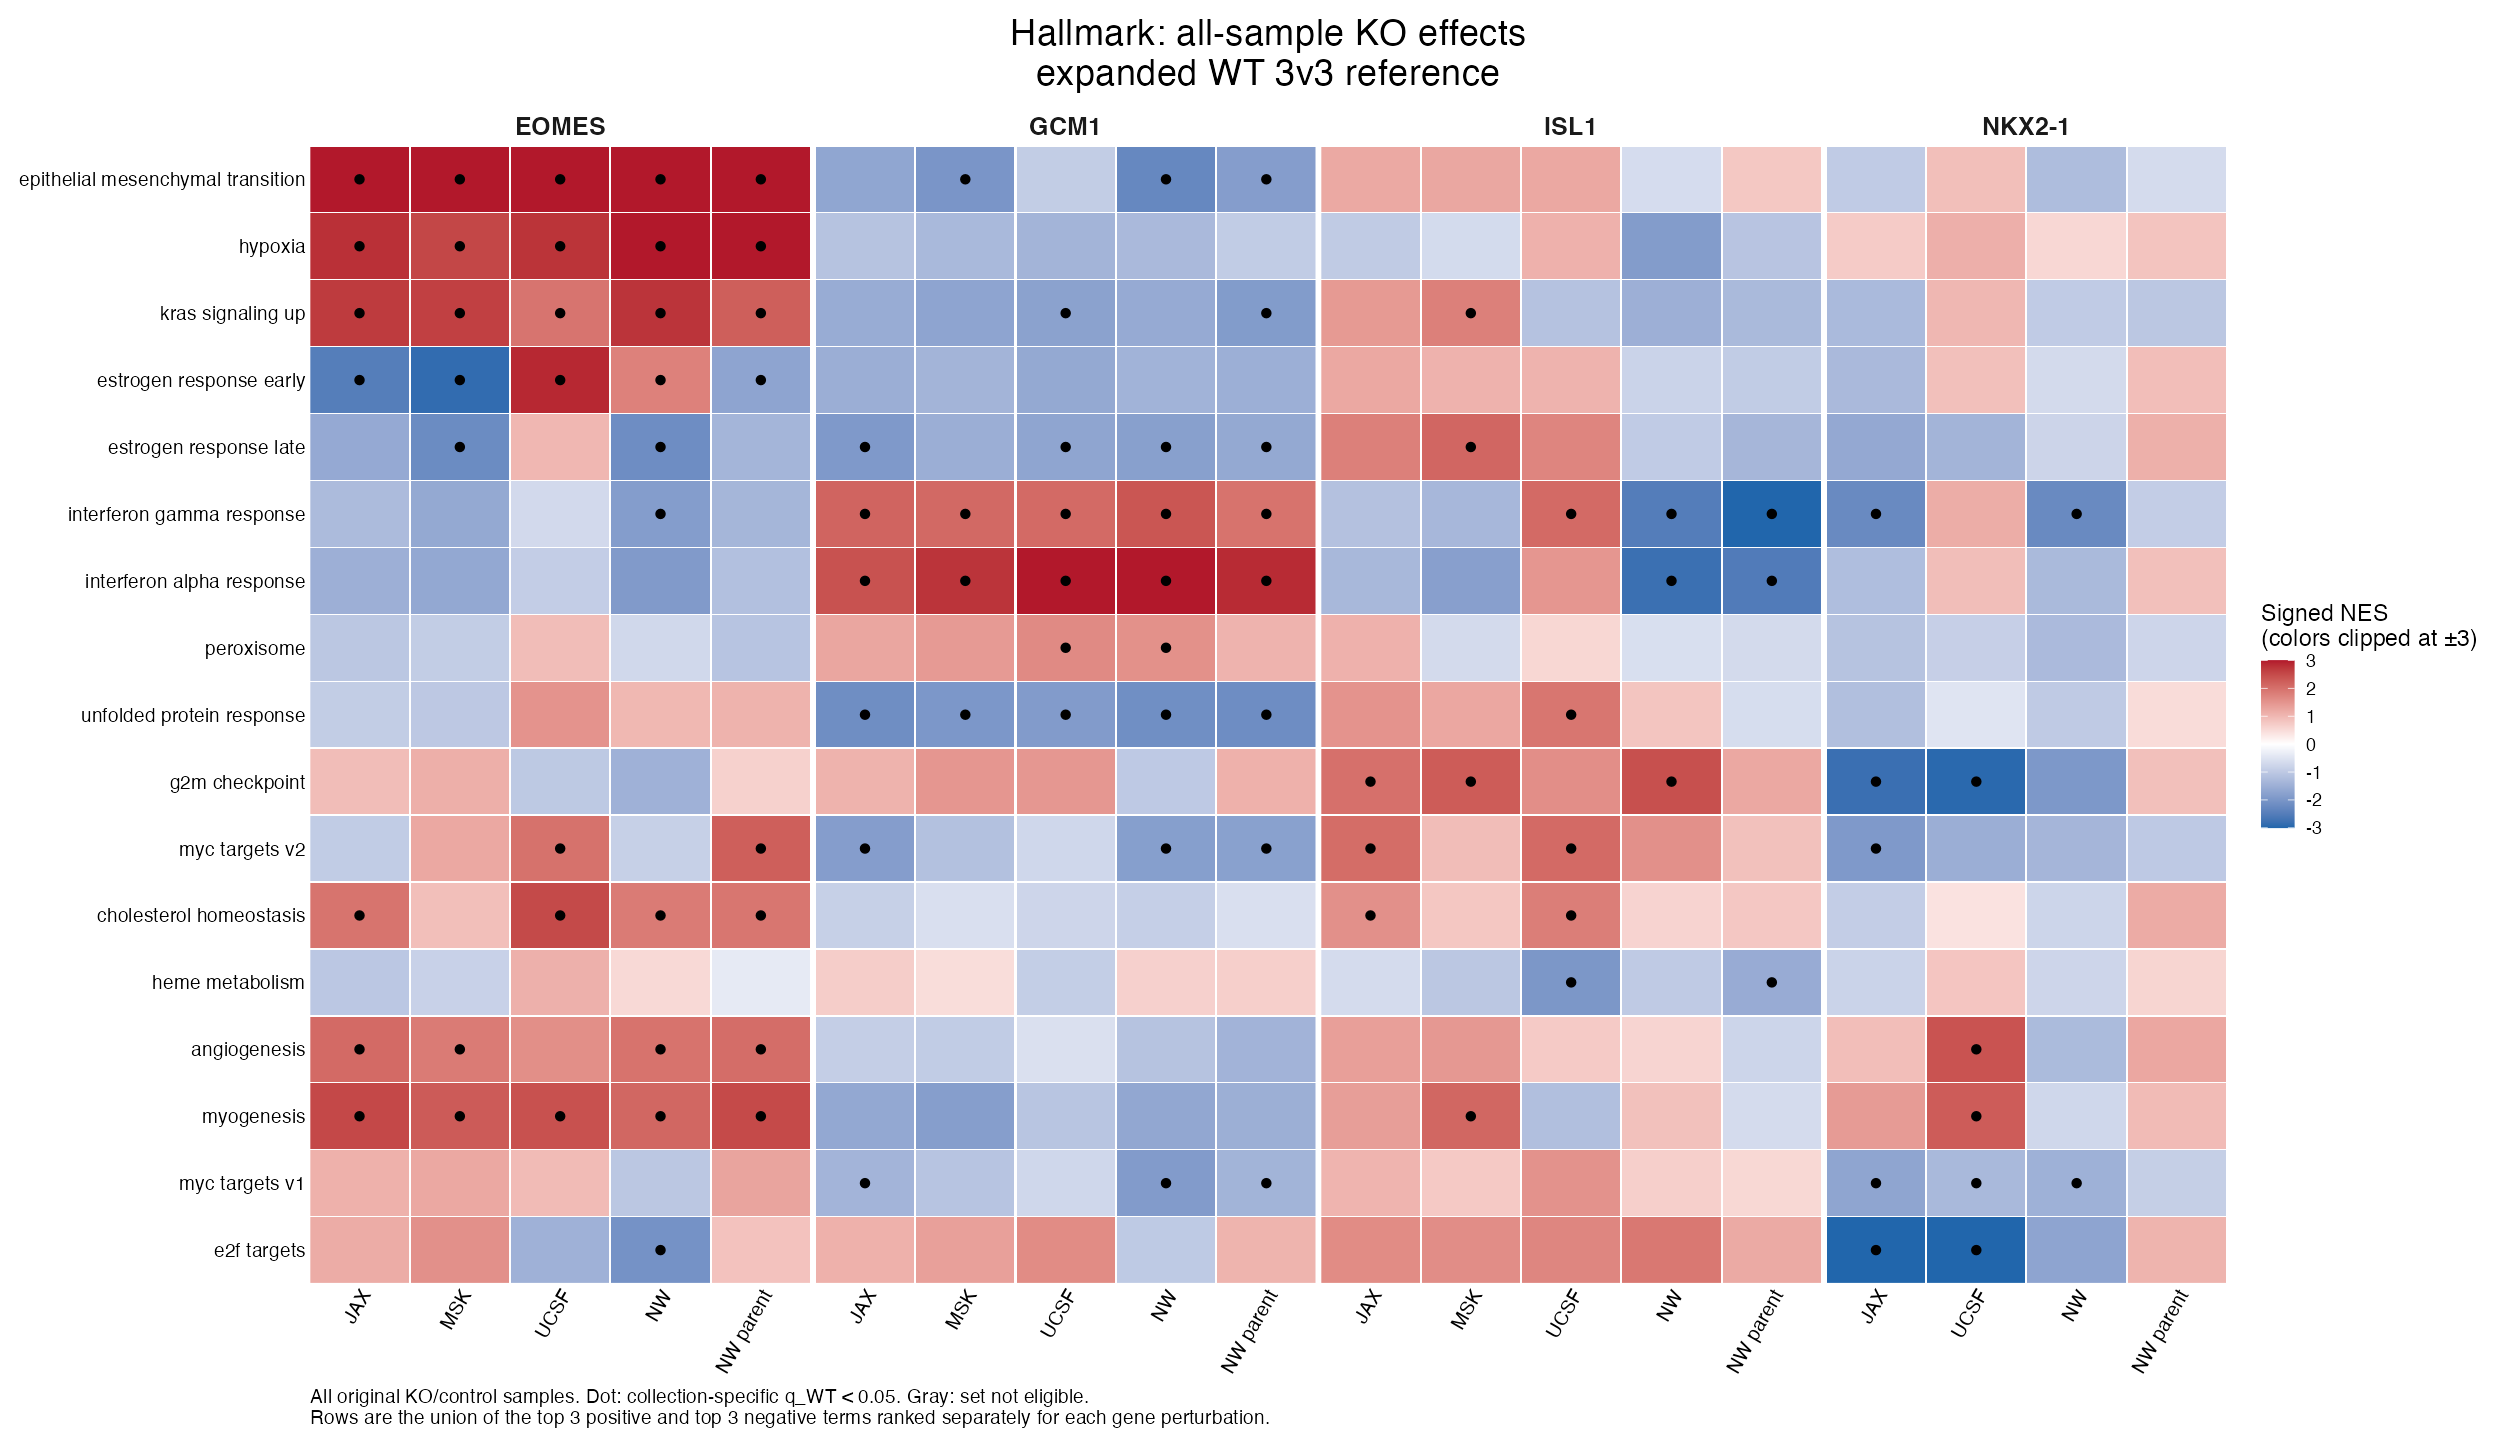

In [11]:
make_full_ko_top_heatmap("Hallmark")

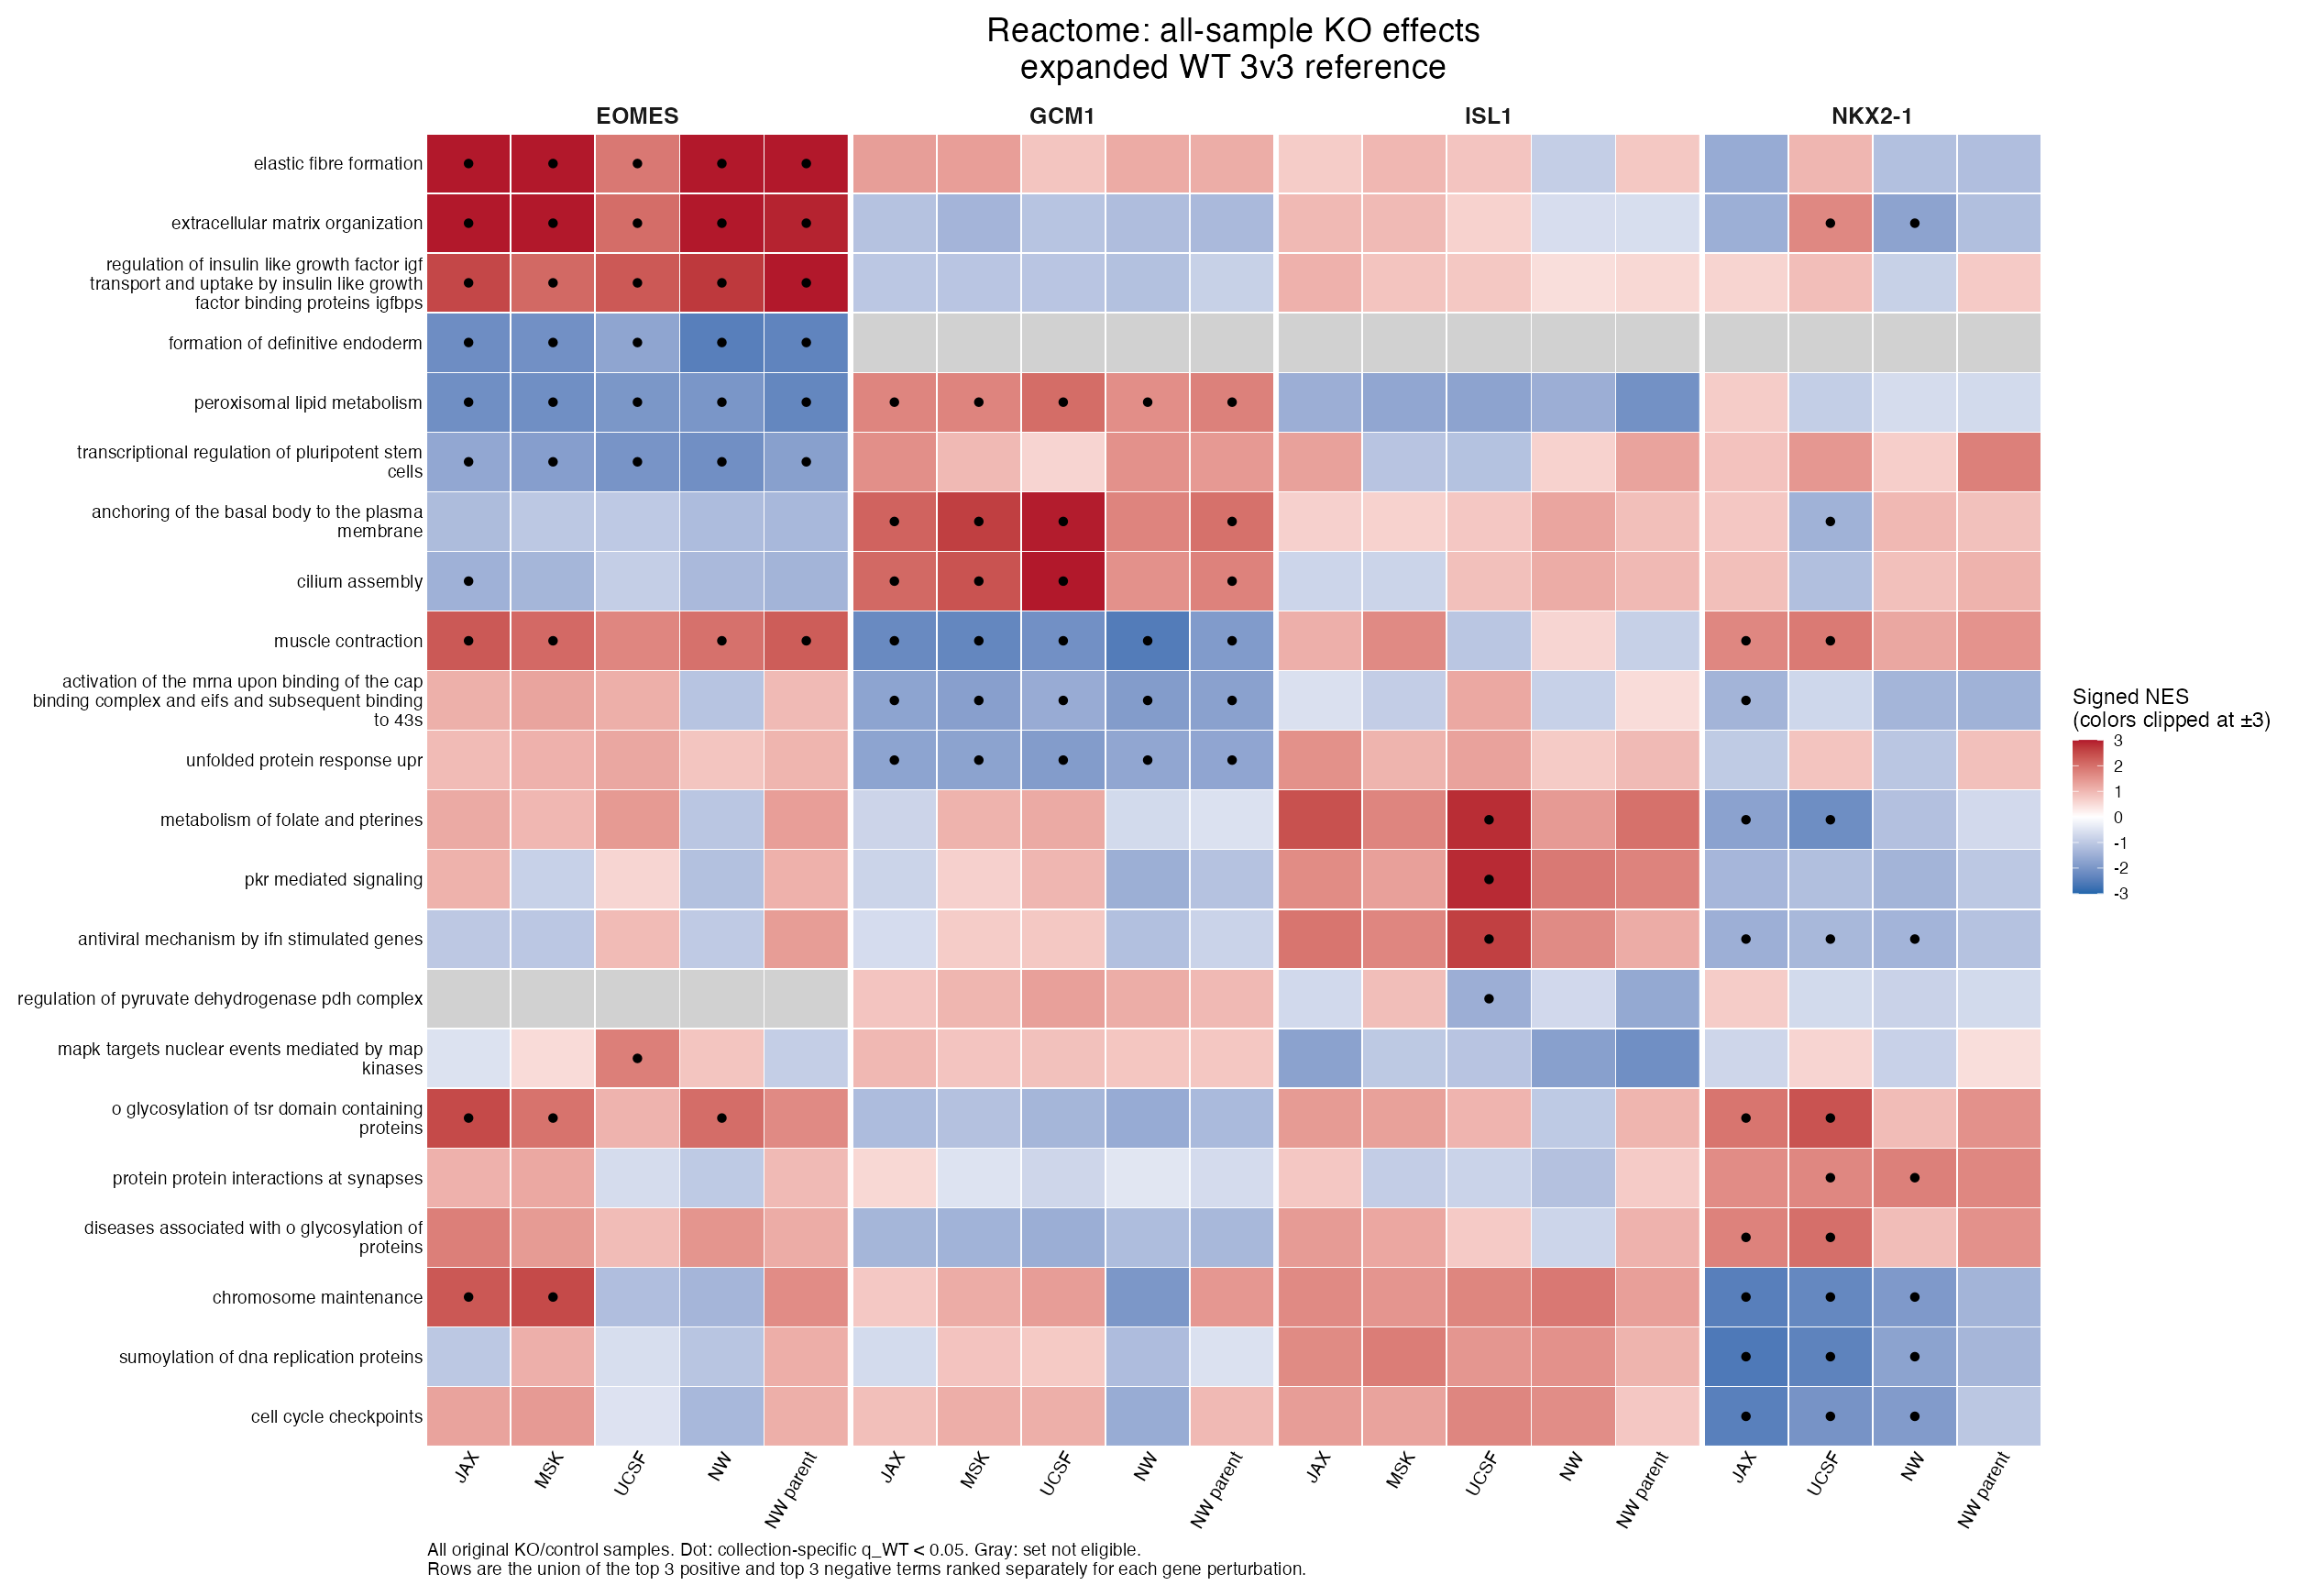

In [12]:
make_full_ko_top_heatmap("Reactome")

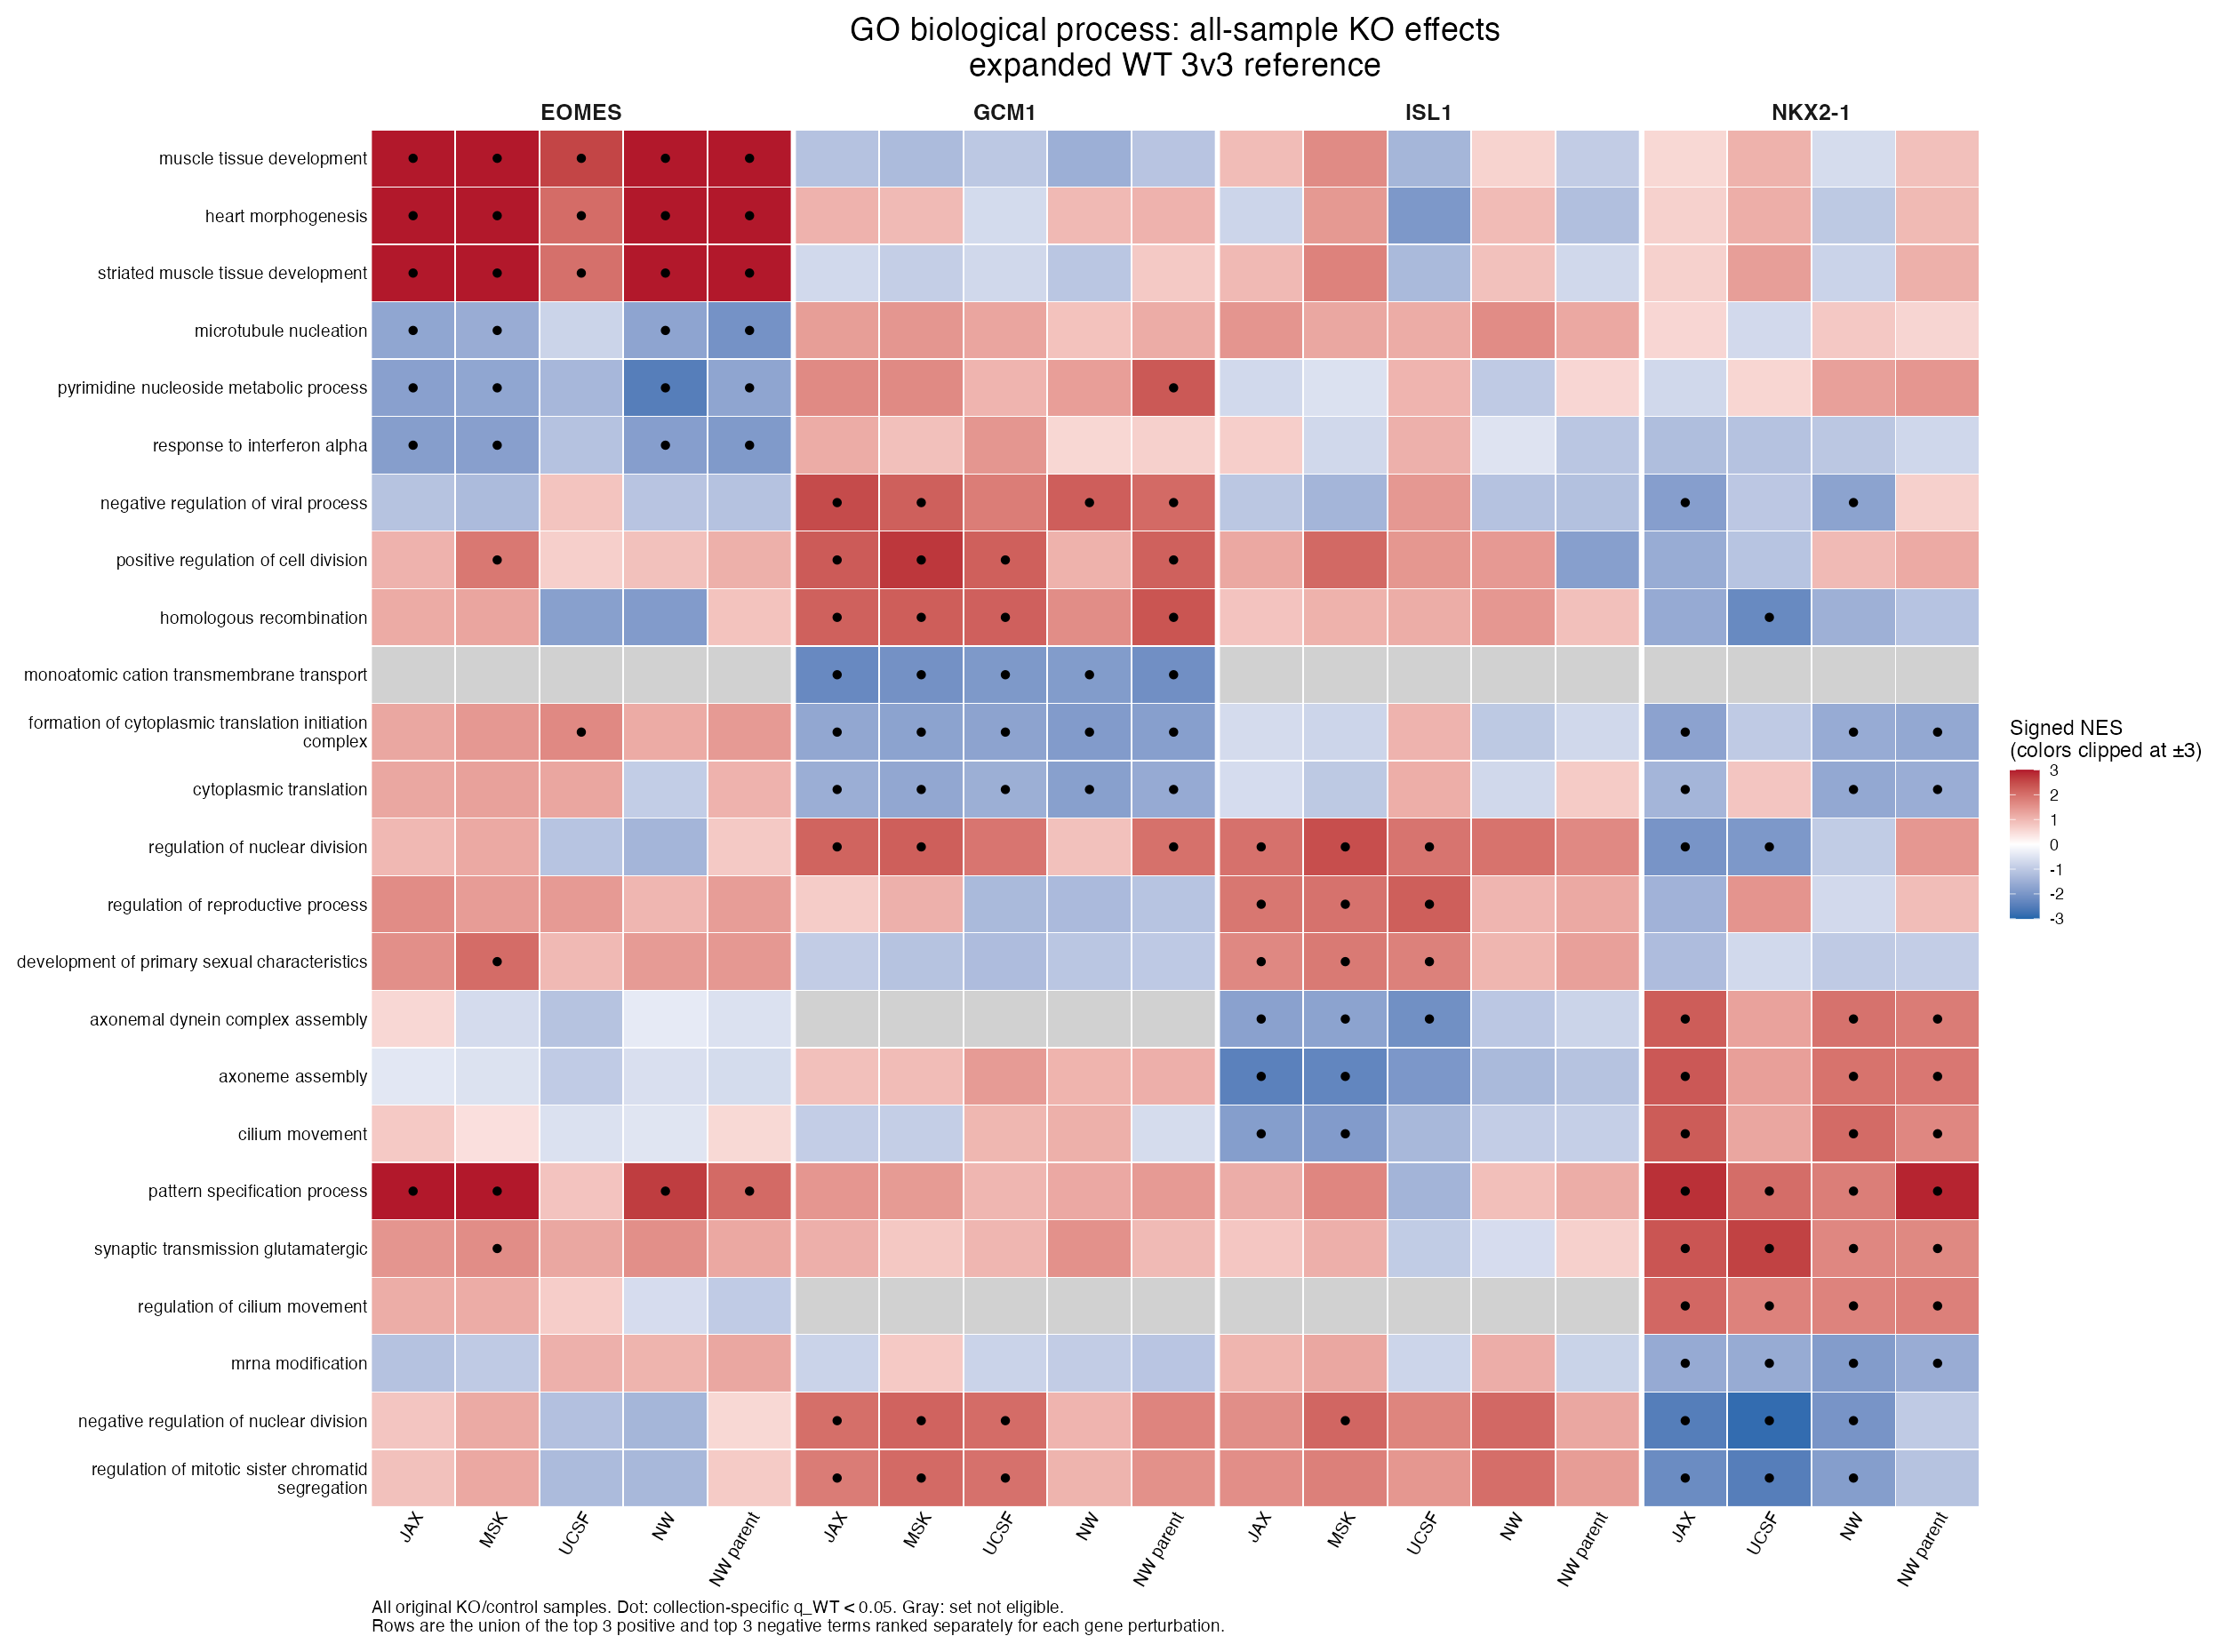

In [13]:
make_full_ko_top_heatmap("GO_BP")

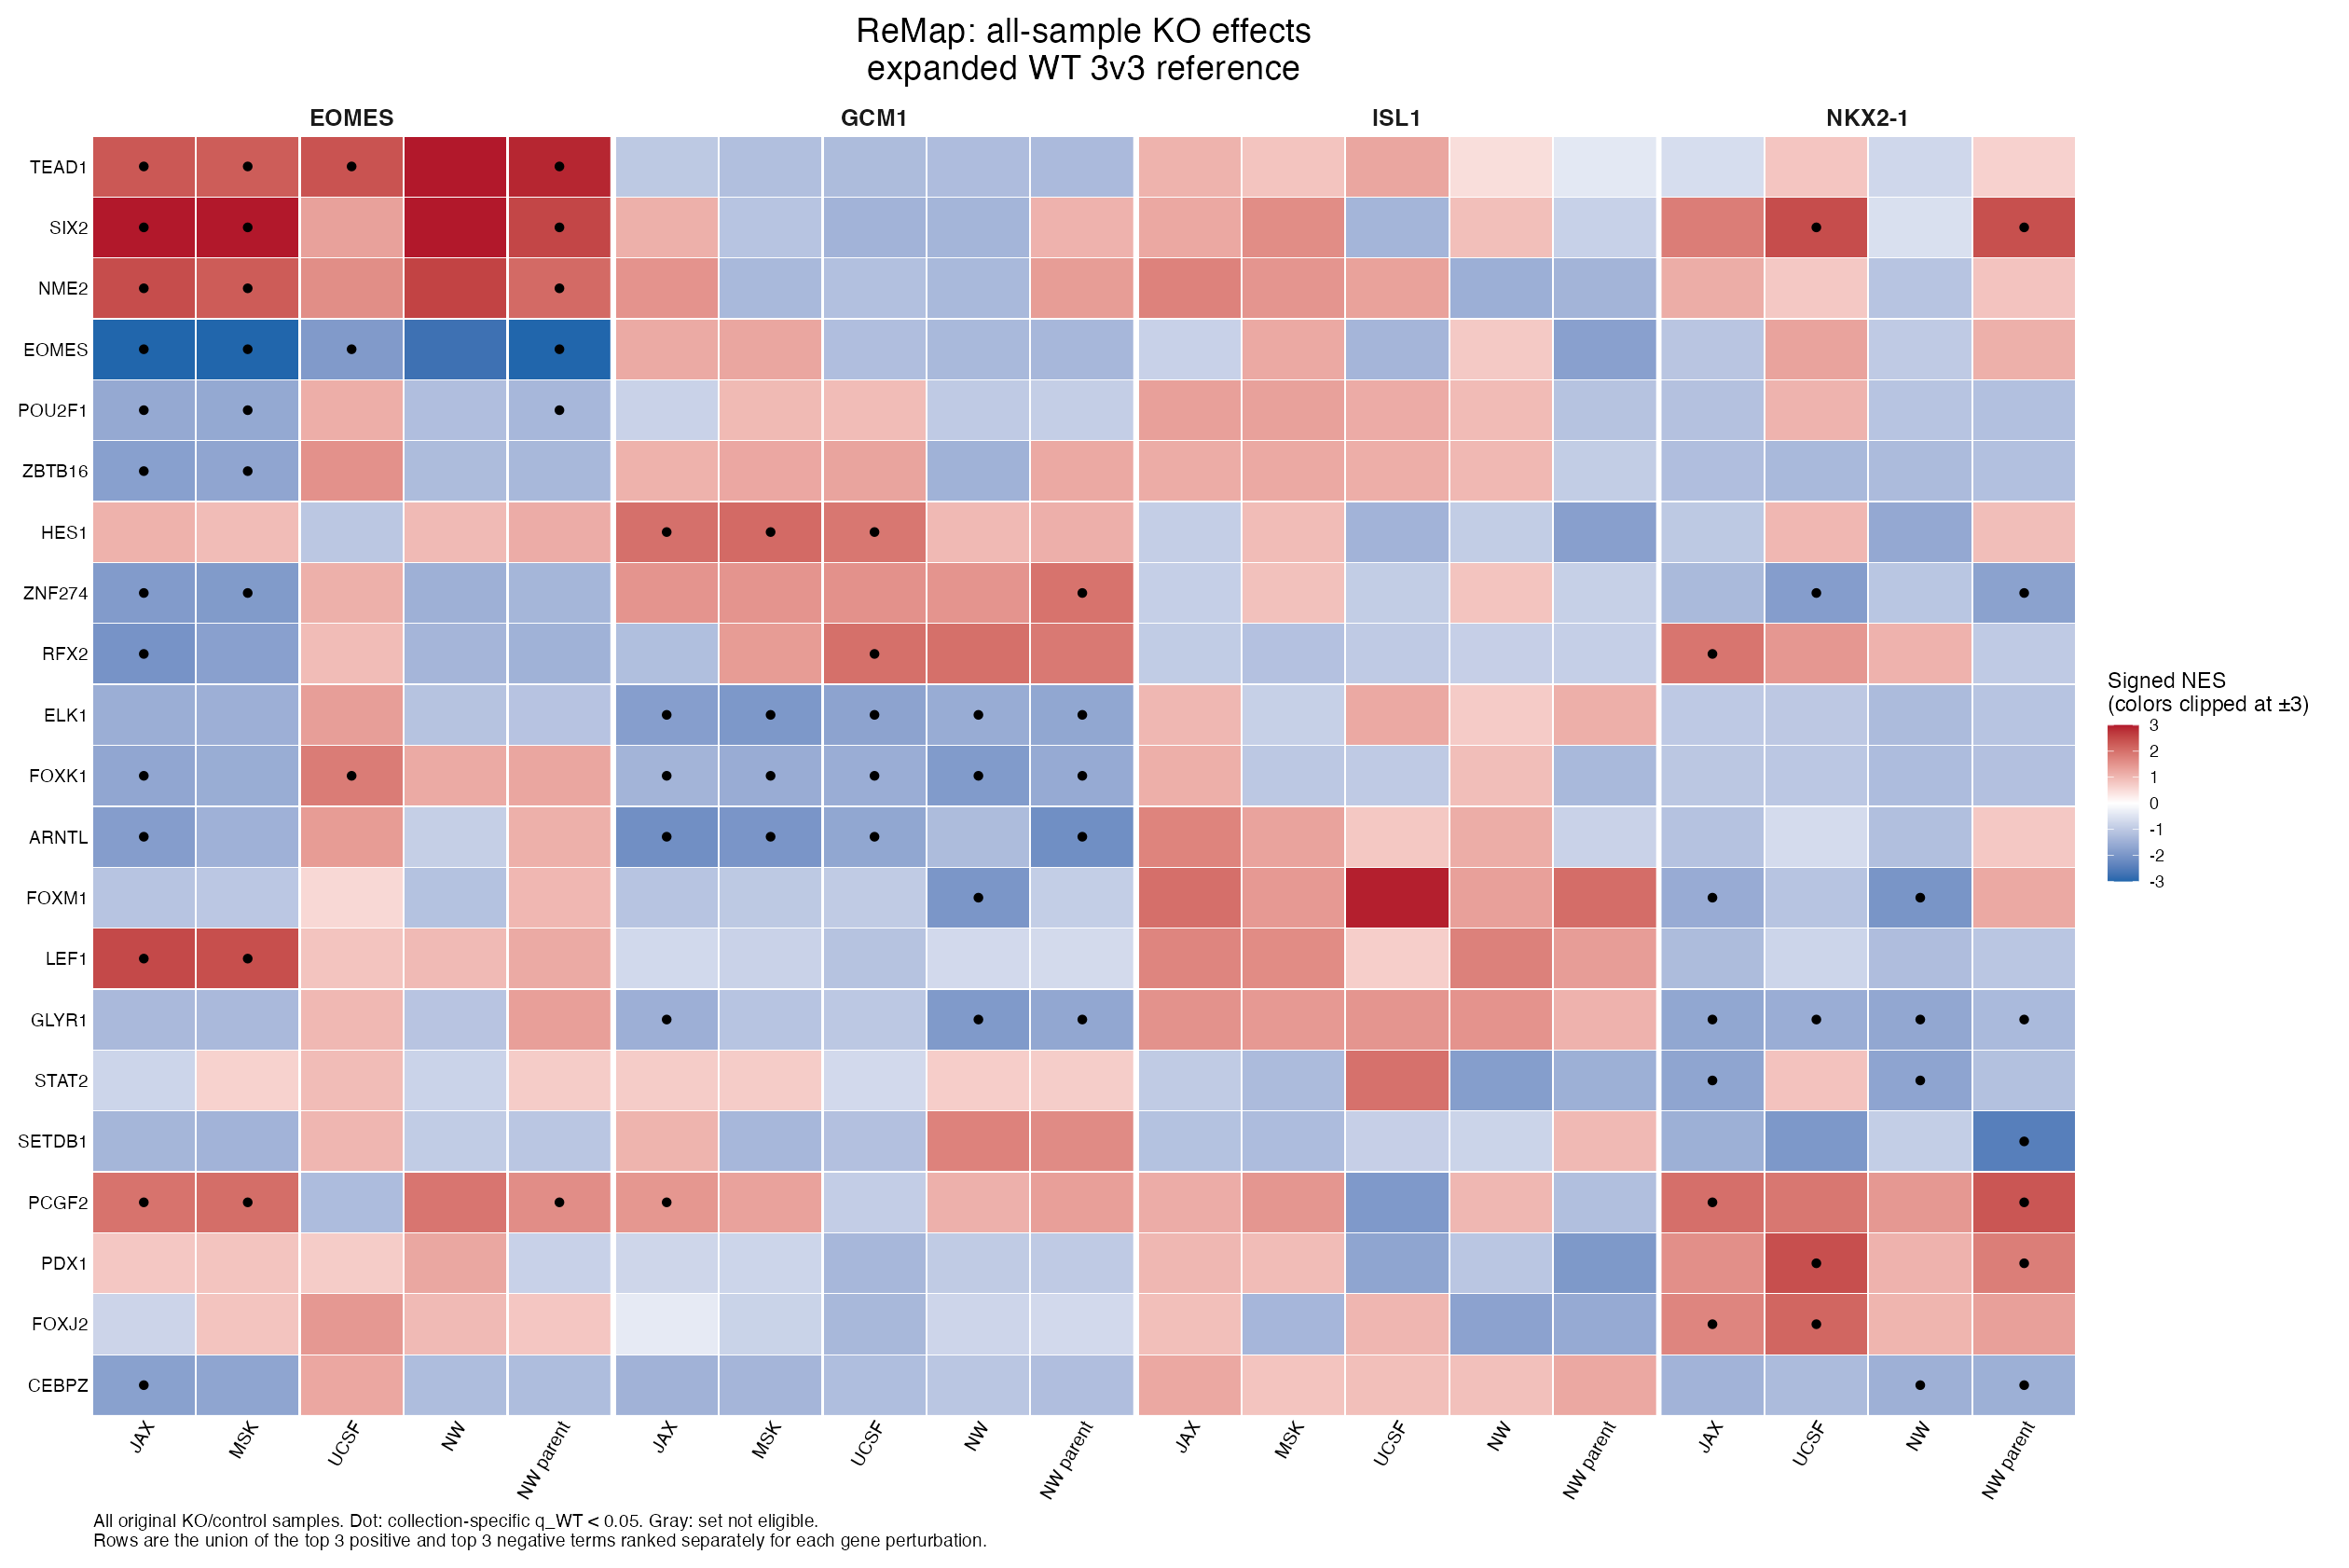

In [14]:
make_full_ko_top_heatmap("ReMap")

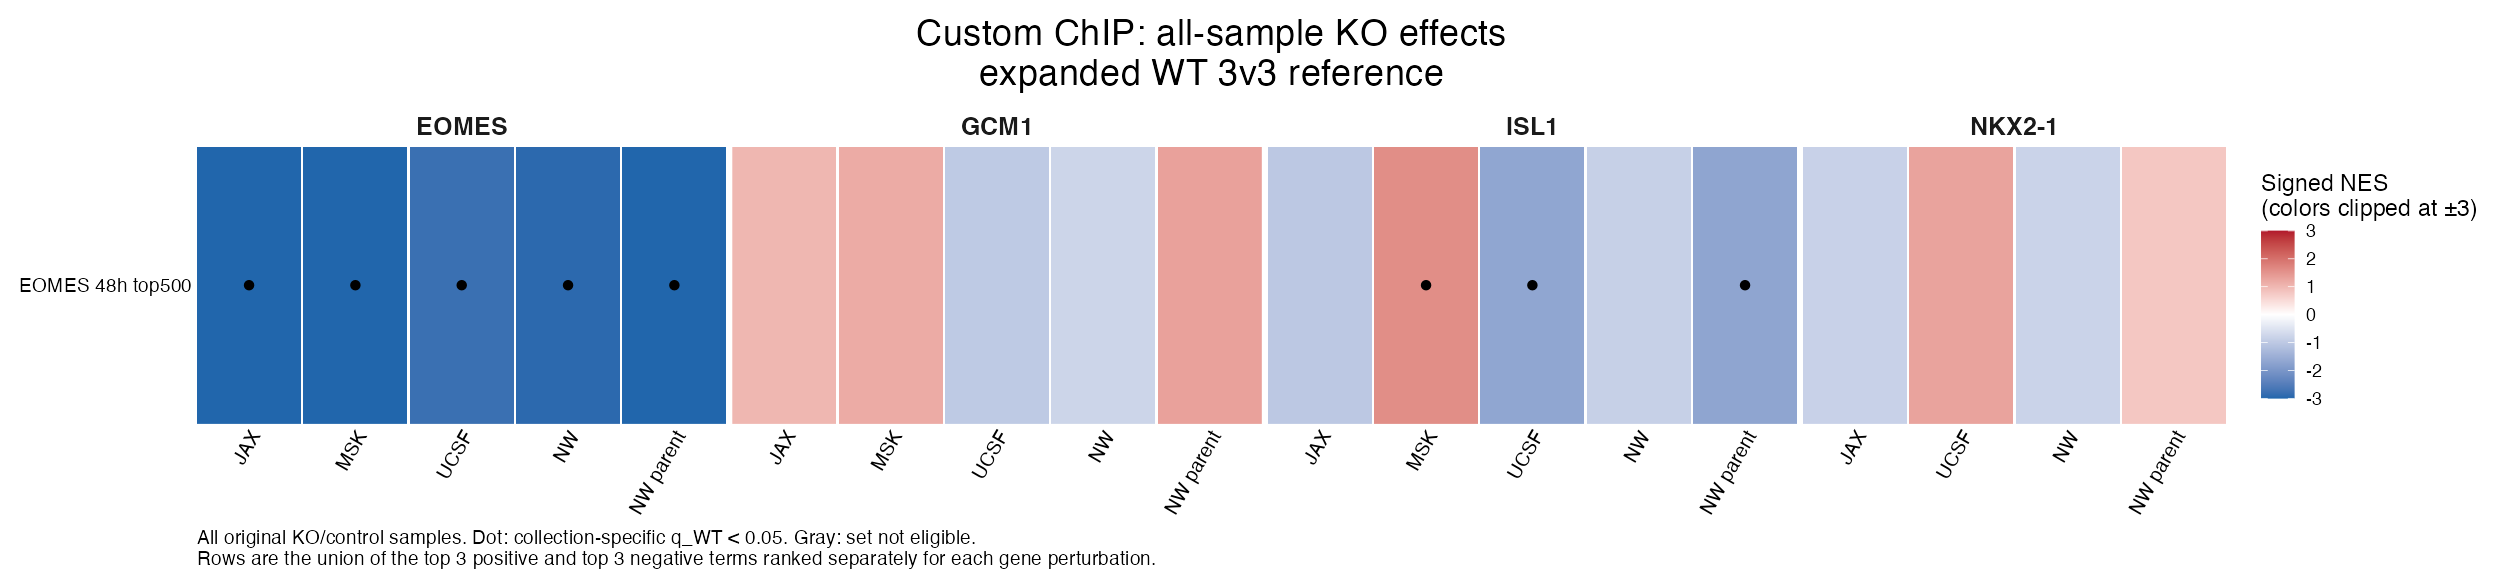

In [15]:
make_full_ko_top_heatmap("Custom_ChIP")

## Interpretation notes

- Ranking is performed within collection because each q-value belongs to a different BH family. A rank of 1 in ReMap is not directly equivalent to a rank of 1 in GO BP.
- The consistency flags summarize recurrence across the available experimental implementations; they do not make those comparisons independent replicates and do not provide a pooled significance test.
- The expanded WT reference contains overlapping WT assignments. More assignments improve empirical resolution but do not create additional biological replicates.
- GO BP contains many overlapping terms, so closely related biological themes can occupy several high ranks. Interpret clusters of related terms rather than treating each label as an independent discovery.
- The complete source table remains unchanged, but NKX2-1/MSK is excluded from this notebook's term selection and heatmaps because of its documented differentiation failure.
- ReMap enrichment indicates that an annotated TF target set is shifted in the ranked list; it does not establish TF activity or direct causality.